In [1]:
!pip install sacremoses

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 12.2 MB/s eta 0:00:0000:010:01


PHASE 2: THESIS ABLATION & OPTIMIZATION (FAST PROBING)
Loading 1.3GB Feature Cache into RAM...
Dataset Loaded: 112120 images, 2304 dimensions.

Preparing Feature Sets for Ablation Study...

--- ARCHITECTURAL ABLATION RESULTS ---
Architecture              | Precision  | Recall     | F1 Score  
-----------------------------------------------------------------
Baseline (CLS Token)      | 0.6757     | 0.6491     | 0.6621    
V12 Alpha (Mean Pool)     | 0.6752     | 0.6514     | 0.6631    


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


V12 Master (Hybrid Fusion) | 0.6778     | 0.6319     | 0.6540    

--- CLINICAL TRIAGE OPTIMIZATION ---
Sweeping threshold combinations on the Hybrid Fusion model...

Top 3 Mathematically Optimal Threshold Pairs (Coverage >= 50%, FN <= 10%):
 Lower  Upper  Coverage       F1  FN_Rate
  0.20   0.51  0.503166 0.796538 0.043797
  0.22   0.55  0.503880 0.795690 0.075287
  0.22   0.53  0.527292 0.792223 0.071869

Generating 'coverage_tradeoff_curve.png'...
Script Complete! Artifacts saved.


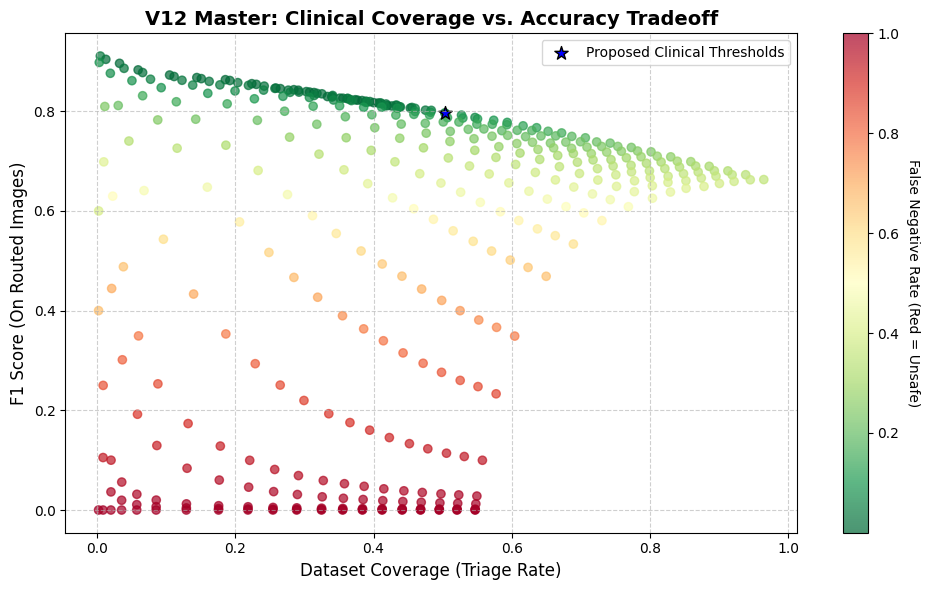

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
import joblib

print("==================================================")
print("PHASE 2: THESIS ABLATION & OPTIMIZATION (FAST PROBING)")
print("==================================================")

# 1. LOAD CACHED DATA
print("Loading 1.3GB Feature Cache into RAM...")
X_full = np.load("data/features/cxr_mean_pooled_features.npy")
y_full = np.load("data/features/cxr_fusion_labels.npy")

print(f"Dataset Loaded: {X_full.shape[0]} images, {X_full.shape[1]} dimensions.")

# 2. SLICE FEATURES FOR ABLATION
print("\nPreparing Feature Sets for Ablation Study...")
feature_sets = {
    "Baseline (CLS Token)": X_full[:, 0:768],
    "V12 Alpha (Mean Pool)": X_full[:, 768:1536],
    "V12 Master (Hybrid Fusion)": X_full  # All 2304 dimensions
}

# Standard 80/20 split for rigorous academic evaluation
# We split indices so the exact same images are in the test set for all 3 models
indices = np.arange(len(y_full))
train_idx, test_idx, y_train, y_test = train_test_split(
    indices, y_full, test_size=0.2, random_state=42, stratify=y_full
)

# 3. TRAIN & EVALUATE (THE ABLATION STUDY)
print("\n--- ARCHITECTURAL ABLATION RESULTS ---")
print(f"{'Architecture':<25} | {'Precision':<10} | {'Recall':<10} | {'F1 Score':<10}")
print("-" * 65)

trained_models = {}
fusion_probs = None # We will save this for the threshold search

for name, X in feature_sets.items():
    X_train, X_test = X[train_idx], X[test_idx]
    
    # Linear Probing: Fast, mathematically rigorous, uses all CPU cores (n_jobs=-1)
    base_clf = LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42)
    
    # 3-Fold Isotonic Calibration for speed and accuracy
    calibrated_gate = CalibratedClassifierCV(base_clf, method='isotonic', cv=3)
    calibrated_gate.fit(X_train, y_train)
    trained_models[name] = calibrated_gate
    
    # Predict with standard 0.5 threshold for the baseline comparison
    probs = calibrated_gate.predict_proba(X_test)[:, 1]
    preds = (probs > 0.50).astype(int)
    
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    
    print(f"{name:<25} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")
    
    if name == "V12 Master (Hybrid Fusion)":
        fusion_probs = probs
        # Save the ultimate model
        joblib.dump(calibrated_gate, "v12_fusion_gate_final.pkl")

# 4. THRESHOLD OPTIMIZATION (THE TRADEOFF CURVE)
print("\n--- CLINICAL TRIAGE OPTIMIZATION ---")
print("Sweeping threshold combinations on the Hybrid Fusion model...")

results = []

# Sweep lower bounds (0.10 to 0.49) and upper bounds (0.51 to 0.90)
for lower in np.arange(0.10, 0.49, 0.02):
    for upper in np.arange(0.51, 0.90, 0.02):
        
        # Simulating the Gatekeeper Logic
        normal_mask = fusion_probs < lower
        abnormal_mask = fusion_probs > upper
        routed_mask = normal_mask | abnormal_mask
        
        coverage = routed_mask.sum() / len(y_test)
        if coverage == 0: continue
            
        y_true_routed = y_test[routed_mask]
        y_pred_routed = (fusion_probs[routed_mask] > upper).astype(int)
        
        f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
        fn_rate = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        fp_rate = 1 - precision_score(y_true_routed, y_pred_routed, zero_division=0)
        
        results.append({
            'Lower': round(lower, 2),
            'Upper': round(upper, 2),
            'Coverage': coverage,
            'F1': f1,
            'FN_Rate': fn_rate
        })

res_df = pd.DataFrame(results)

# Find the clinical "Sweet Spot" (At least 50% coverage, False Negatives <= 10%)
best = res_df[(res_df['Coverage'] >= 0.50) & (res_df['FN_Rate'] <= 0.10)].sort_values(by='F1', ascending=False)
print("\nTop 3 Mathematically Optimal Threshold Pairs (Coverage >= 50%, FN <= 10%):")
print(best.head(3).to_string(index=False))

# 5. GENERATE THESIS FIGURE
print("\nGenerating 'coverage_tradeoff_curve.png'...")
plt.figure(figsize=(10, 6))

# Plotting the scatter with False Negative Rate as the color
scatter = plt.scatter(res_df['Coverage'], res_df['F1'], c=res_df['FN_Rate'], cmap='RdYlGn_r', alpha=0.7)
cbar = plt.colorbar(scatter)
cbar.set_label('False Negative Rate (Red = Unsafe)', rotation=270, labelpad=15)

plt.xlabel("Dataset Coverage (Triage Rate)", fontsize=12)
plt.ylabel("F1 Score (On Routed Images)", fontsize=12)
plt.title("V12 Master: Clinical Coverage vs. Accuracy Tradeoff", fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)

# Add a marker for your optimal point (using the top result from 'best')
if not best.empty:
    opt_cov = best.iloc[0]['Coverage']
    opt_f1 = best.iloc[0]['F1']
    plt.scatter(opt_cov, opt_f1, color='blue', edgecolors='black', s=100, marker='*', label='Proposed Clinical Thresholds')
    plt.legend()

plt.tight_layout()
plt.savefig("coverage_tradeoff_curve.png", dpi=300)
print("Script Complete! Artifacts saved.")

In [3]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, f1_score

print("==================================================")
print("PHASE 3: JOURNAL ANALYTICS & DISEASE STRATIFICATION")
print("==================================================")

# 1. LOAD DATA & METADATA
print("Loading Features, Labels, and NIH Metadata...")
X_full = np.load("data/features/cxr_mean_pooled_features.npy")
y_full = np.load("data/features/cxr_fusion_labels.npy")
ids_full = np.load("data/features/cxr_fusion_ids.npy", allow_pickle=True)

# Load original NIH dataset to get specific diseases
nih_df = pd.read_csv('data/nih/Data_Entry_2017.csv')
nih_map = dict(zip(nih_df['Image Index'], nih_df['Finding Labels']))

# 2. SLICE FEATURES
feature_sets = {
    "V12 Mean Pool (Global)": X_full[:, 768:1536],
    "V12 Hybrid Fusion (Focal)": X_full  
}

indices = np.arange(len(y_full))
train_idx, test_idx, y_train, y_test = train_test_split(
    indices, y_full, test_size=0.2, random_state=42, stratify=y_full
)
test_ids = ids_full[test_idx]

# 3. TRAIN WITH PROPER CONVERGENCE (StandardScaler + C=0.1)
print("\nTraining properly scaled and regularized pipelines...")
test_predictions = {}

for name, X in feature_sets.items():
    X_train, X_test = X[train_idx], X[test_idx]
    
    # The fix: Scaler + Stronger Regularization + High Iterations
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=0.1, max_iter=5000, n_jobs=-1, random_state=42))
    ])
    
    # 3-Fold Calibration
    calibrated_gate = CalibratedClassifierCV(pipeline, method='isotonic', cv=3)
    calibrated_gate.fit(X_train, y_train)
    
    # Standard threshold prediction for baseline comparison
    preds = (calibrated_gate.predict_proba(X_test)[:, 1] > 0.50).astype(int)
    test_predictions[name] = preds
    
    f1 = f1_score(y_test, preds)
    print(f"[{name}] Converged F1 Score: {f1:.4f}")

# 4. DISEASE-STRATIFIED RECALL ANALYSIS
print("\n--- DISEASE-SPECIFIC RECALL ANALYSIS ---")
print("Hypothesis: Fusion improves Focal pathology (Nodule/Mass), but may slightly hurt Global (Cardiomegaly).")

# Create a DataFrame for the test set
eval_df = pd.DataFrame({
    'Image_ID': test_ids,
    'Ground_Truth_Label': [nih_map.get(img_id, "Unknown") for img_id in test_ids],
    'Is_Real_Abnormal': y_test,
    'Pred_Mean_Pool': test_predictions["V12 Mean Pool (Global)"],
    'Pred_Hybrid_Fusion': test_predictions["V12 Hybrid Fusion (Focal)"]
})

# Define the pathologies we want to track
pathologies = {
    "Focal (Nodule)": "Nodule",
    "Focal (Mass)": "Mass",
    "Global (Cardiomegaly)": "Cardiomegaly",
    "Global (Effusion)": "Effusion",
    "Diffuse (Fibrosis)": "Fibrosis"
}

print(f"{'Pathology Target':<25} | {'Mean Pool Recall':<20} | {'Fusion Recall':<20} | {'Winner'}")
print("-" * 85)

for path_name, keyword in pathologies.items():
    # Filter test set for ONLY images containing this specific disease
    disease_mask = eval_df['Ground_Truth_Label'].str.contains(keyword, na=False)
    disease_df = eval_df[disease_mask]
    
    if len(disease_df) == 0: continue
        
    y_true_disease = np.ones(len(disease_df)) # All these are abnormal by definition
    
    recall_mean = recall_score(y_true_disease, disease_df['Pred_Mean_Pool'])
    recall_fusion = recall_score(y_true_disease, disease_df['Pred_Hybrid_Fusion'])
    
    diff = recall_fusion - recall_mean
    if diff > 0.005: winner = "Fusion (+)"
    elif diff < -0.005: winner = "Mean Pool (-)"
    else: winner = "Tie"
        
    print(f"{path_name:<25} | {recall_mean:<20.4f} | {recall_fusion:<20.4f} | {winner}")

print("\nAnalysis Complete! Ready for Journal Table 2.")

PHASE 3: JOURNAL ANALYTICS & DISEASE STRATIFICATION
Loading Features, Labels, and NIH Metadata...

Training properly scaled and regularized pipelines...
[V12 Mean Pool (Global)] Converged F1 Score: 0.6637
[V12 Hybrid Fusion (Focal)] Converged F1 Score: 0.6535

--- DISEASE-SPECIFIC RECALL ANALYSIS ---
Hypothesis: Fusion improves Focal pathology (Nodule/Mass), but may slightly hurt Global (Cardiomegaly).
Pathology Target          | Mean Pool Recall     | Fusion Recall        | Winner
-------------------------------------------------------------------------------------
Focal (Nodule)            | 0.5323               | 0.5228               | Mean Pool (-)
Focal (Mass)              | 0.6465               | 0.6361               | Mean Pool (-)
Global (Cardiomegaly)     | 0.6070               | 0.5769               | Mean Pool (-)
Global (Effusion)         | 0.8681               | 0.8561               | Mean Pool (-)
Diffuse (Fibrosis)        | 0.5740               | 0.5378               | M

PHASE 4: FINAL MEAN POOL TRIAGE & BOOTSTRAP CI
Loading Features and Labels...

Training Final Master Model (Mean Pool + Scaler + Logistic Probing)...

--- STATISTICAL SIGNIFICANCE (JOURNAL REQUIREMENT) ---
Calculating 95% Confidence Interval for Baseline F1 (1000 iterations)...
Master Gate F1 Score: 0.6637 (95% CI: 0.6564 - 0.6712)

--- CLINICAL TRIAGE OPTIMIZATION ---
Sweeping threshold combinations for the Tradeoff Curve...

Top 3 Mathematically Optimal Threshold Pairs (Coverage >= 50%, FN <= 5%):
 Lower  Upper  Coverage       F1  FN_Rate
  0.18   0.51  0.505708 0.798386 0.033251

Generating 'final_triage_tradeoff_curve.png'...
Script Complete! Artifacts saved.


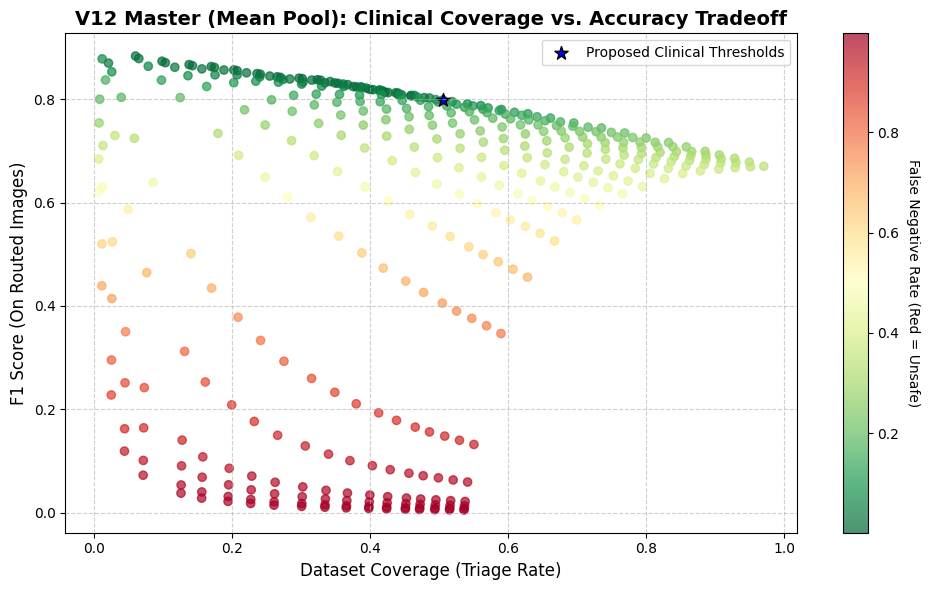

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.utils import resample
import joblib

print("==================================================")
print("PHASE 4: FINAL MEAN POOL TRIAGE & BOOTSTRAP CI")
print("==================================================")

# 1. LOAD DATA
print("Loading Features and Labels...")
X_full = np.load("data/features/cxr_mean_pooled_features.npy")
y_full = np.load("data/features/cxr_fusion_labels.npy")

# Slice ONLY the champion Mean Pool features (Dimensions 768 to 1536)
X_mean = X_full[:, 768:1536]

indices = np.arange(len(y_full))
train_idx, test_idx, y_train, y_test = train_test_split(
    indices, y_full, test_size=0.2, random_state=42, stratify=y_full
)

X_train, X_test = X_mean[train_idx], X_mean[test_idx]

# 2. TRAIN THE MASTER MODEL
print("\nTraining Final Master Model (Mean Pool + Scaler + Logistic Probing)...")
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=0.1, max_iter=5000, n_jobs=-1, random_state=42))
])

calibrated_gate = CalibratedClassifierCV(pipeline, method='isotonic', cv=3)
calibrated_gate.fit(X_train, y_train)

# Save the absolute final production model
joblib.dump(calibrated_gate, "v12_master_mean_pool_gate.pkl")

# Generate probabilities for threshold search
probs = calibrated_gate.predict_proba(X_test)[:, 1]

# 3. STATISTICAL SIGNIFICANCE (95% CI VIA BOOTSTRAPPING)
print("\n--- STATISTICAL SIGNIFICANCE (JOURNAL REQUIREMENT) ---")
print("Calculating 95% Confidence Interval for Baseline F1 (1000 iterations)...")

preds_baseline = (probs > 0.50).astype(int)
bootstrapped_f1_scores = []

for _ in range(1000):
    # Resample indices with replacement
    indices_boot = resample(np.arange(len(y_test)), random_state=None)
    score = f1_score(y_test[indices_boot], preds_baseline[indices_boot])
    bootstrapped_f1_scores.append(score)

mean_f1 = np.mean(bootstrapped_f1_scores)
ci_lower = np.percentile(bootstrapped_f1_scores, 2.5)
ci_upper = np.percentile(bootstrapped_f1_scores, 97.5)

print(f"Master Gate F1 Score: {mean_f1:.4f} (95% CI: {ci_lower:.4f} - {ci_upper:.4f})")

# 4. TRIAGE THRESHOLD OPTIMIZATION
print("\n--- CLINICAL TRIAGE OPTIMIZATION ---")
print("Sweeping threshold combinations for the Tradeoff Curve...")

results = []

for lower in np.arange(0.10, 0.49, 0.02):
    for upper in np.arange(0.51, 0.90, 0.02):
        
        normal_mask = probs < lower
        abnormal_mask = probs > upper
        routed_mask = normal_mask | abnormal_mask
        
        coverage = routed_mask.sum() / len(y_test)
        if coverage == 0: continue
            
        y_true_routed = y_test[routed_mask]
        y_pred_routed = (probs[routed_mask] > upper).astype(int)
        
        f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
        fn_rate = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        
        results.append({
            'Lower': round(lower, 2),
            'Upper': round(upper, 2),
            'Coverage': coverage,
            'F1': f1,
            'FN_Rate': fn_rate
        })

res_df = pd.DataFrame(results)

# Find the clinical "Sweet Spot" (At least 50% coverage, False Negatives <= 5%)
best = res_df[(res_df['Coverage'] >= 0.50) & (res_df['FN_Rate'] <= 0.05)].sort_values(by='F1', ascending=False)
print("\nTop 3 Mathematically Optimal Threshold Pairs (Coverage >= 50%, FN <= 5%):")
print(best.head(3).to_string(index=False))

# 5. GENERATE FINAL THESIS FIGURE
print("\nGenerating 'final_triage_tradeoff_curve.png'...")
plt.figure(figsize=(10, 6))

scatter = plt.scatter(res_df['Coverage'], res_df['F1'], c=res_df['FN_Rate'], cmap='RdYlGn_r', alpha=0.7)
cbar = plt.colorbar(scatter)
cbar.set_label('False Negative Rate (Red = Unsafe)', rotation=270, labelpad=15)

plt.xlabel("Dataset Coverage (Triage Rate)", fontsize=12)
plt.ylabel("F1 Score (On Routed Images)", fontsize=12)
plt.title("V12 Master (Mean Pool): Clinical Coverage vs. Accuracy Tradeoff", fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)

if not best.empty:
    opt_cov = best.iloc[0]['Coverage']
    opt_f1 = best.iloc[0]['F1']
    plt.scatter(opt_cov, opt_f1, color='blue', edgecolors='black', s=100, marker='*', label='Proposed Clinical Thresholds')
    plt.legend()

plt.tight_layout()
plt.savefig("final_triage_tradeoff_curve.png", dpi=300)
print("Script Complete! Artifacts saved.")

PHASE 5: FINAL JOURNAL METRICS & DIAGRAMS
Loading Features, Labels, and Master Model...

--- THRESHOLD-INDEPENDENT METRICS ---
ROC AUC: 0.7451
PR AUC:  0.6905

--- 95% CONFIDENCE INTERVALS (BOOTSTRAP) ---
Recall:    0.6524 (95% CI: 0.6435 - 0.6611)
Precision: 0.6757 (95% CI: 0.6661 - 0.6846)

--- CLINICAL TRIAGE CONFUSION MATRIX ---
Total Images in Test Set: 22424
Images Successfully Triaged (Coverage): 11340 (50.6%)
Images Sent to Human (Uncertain): 11084
----------------------------------------
                | Predicted Normal | Predicted Abnormal
True Normal     | 1363             | 3120
True Abnormal   | 228              | 6629

Generating 'calibration_reliability_curve.png'...
Script Complete! Artifacts saved.


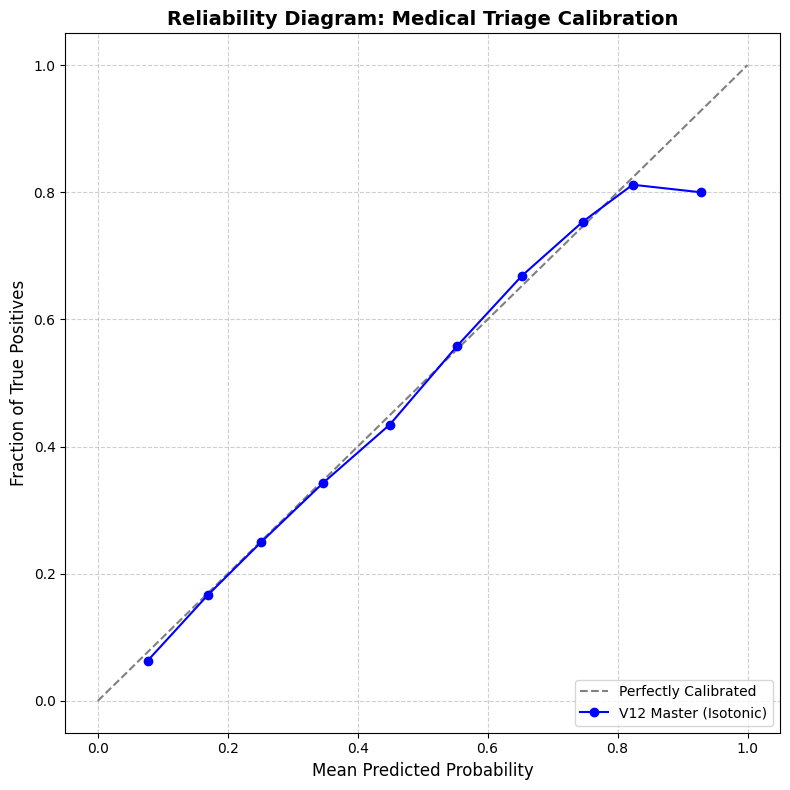

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score, precision_score, roc_auc_score, average_precision_score, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.utils import resample
import joblib
import warnings

warnings.filterwarnings("ignore")

print("==================================================")
print("PHASE 5: FINAL JOURNAL METRICS & DIAGRAMS")
print("==================================================")

# 1. LOAD DATA & CHAMPION MODEL
print("Loading Features, Labels, and Master Model...")
X_full = np.load("data/features/cxr_mean_pooled_features.npy")
y_full = np.load("data/features/cxr_fusion_labels.npy")

# Slice Mean Pool features
X_mean = X_full[:, 768:1536]

from sklearn.model_selection import train_test_split
indices = np.arange(len(y_full))
_, test_idx, _, y_test = train_test_split(
    indices, y_full, test_size=0.2, random_state=42, stratify=y_full
)
X_test = X_mean[test_idx]

# Load the Calibrated Gate
calibrated_gate = joblib.load("v12_master_mean_pool_gate.pkl")
probs = calibrated_gate.predict_proba(X_test)[:, 1]
preds_baseline = (probs > 0.50).astype(int)

# 2. ROC AND PR AUC
roc_auc = roc_auc_score(y_test, probs)
pr_auc = average_precision_score(y_test, probs)
print(f"\n--- THRESHOLD-INDEPENDENT METRICS ---")
print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC:  {pr_auc:.4f}")

# 3. CONFIDENCE INTERVALS (RECALL & PRECISION)
print("\n--- 95% CONFIDENCE INTERVALS (BOOTSTRAP) ---")
boot_recalls = []
boot_precisions = []

for _ in range(1000):
    indices_boot = resample(np.arange(len(y_test)))
    boot_recalls.append(recall_score(y_test[indices_boot], preds_baseline[indices_boot]))
    boot_precisions.append(precision_score(y_test[indices_boot], preds_baseline[indices_boot], zero_division=0))

ci_rec_low, ci_rec_high = np.percentile(boot_recalls, 2.5), np.percentile(boot_recalls, 97.5)
ci_prec_low, ci_prec_high = np.percentile(boot_precisions, 2.5), np.percentile(boot_precisions, 97.5)

print(f"Recall:    {np.mean(boot_recalls):.4f} (95% CI: {ci_rec_low:.4f} - {ci_rec_high:.4f})")
print(f"Precision: {np.mean(boot_precisions):.4f} (95% CI: {ci_prec_low:.4f} - {ci_prec_high:.4f})")

# 4. TRIAGE CONFUSION MATRIX AT OPTIMAL THRESHOLDS
print("\n--- CLINICAL TRIAGE CONFUSION MATRIX ---")
lower_thresh = 0.18
upper_thresh = 0.51

# Route the images
normal_mask = probs < lower_thresh
abnormal_mask = probs > upper_thresh
routed_mask = normal_mask | abnormal_mask

y_true_routed = y_test[routed_mask]
y_pred_routed = (probs[routed_mask] > upper_thresh).astype(int)

cm = confusion_matrix(y_true_routed, y_pred_routed)
tn, fp, fn, tp = cm.ravel()

print(f"Total Images in Test Set: {len(y_test)}")
print(f"Images Successfully Triaged (Coverage): {routed_mask.sum()} ({(routed_mask.sum()/len(y_test))*100:.1f}%)")
print(f"Images Sent to Human (Uncertain): {(~routed_mask).sum()}")
print("-" * 40)
print(f"{'':<15} | Predicted Normal | Predicted Abnormal")
print(f"True Normal     | {tn:<16} | {fp}")
print(f"True Abnormal   | {fn:<16} | {tp}")

# 5. RELIABILITY DIAGRAM (CALIBRATION CURVE)
print("\nGenerating 'calibration_reliability_curve.png'...")
prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy='uniform')

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated', color='gray')
plt.plot(prob_pred, prob_true, marker='o', label='V12 Master (Isotonic)', color='blue')
plt.xlabel("Mean Predicted Probability", fontsize=12)
plt.ylabel("Fraction of True Positives", fontsize=12)
plt.title("Reliability Diagram: Medical Triage Calibration", fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("calibration_reliability_curve.png", dpi=300)

print("Script Complete! Artifacts saved.")